# Breast Cancer Classification with Machine Learning

**Author:** Aidan Pfeiffer

This notebook classifies breast tumors as **malignant** or **benign** using the Wisconsin Diagnostic Breast Cancer dataset (built into scikit-learn). Three models are trained on the same data and compared by test accuracy:

- Logistic Regression
- K-Nearest Neighbors
- Random Forest

*Note: in scikit-learn's encoding, `0` = malignant and `1` = benign.*

## 1. Imports

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Data

In [5]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

## 3. Inspect the Data and Check for Missing Values

The dataset has 30 numeric features and no missing values.

In [6]:
print(X.head())
print(X.isnull().sum())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

## 4. Target Distribution

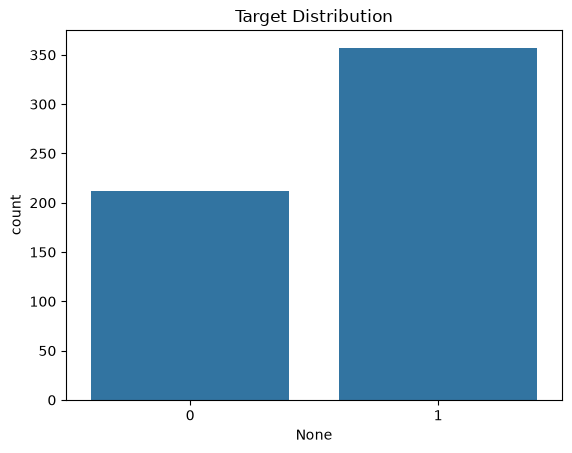

In [7]:
sns.countplot(x=y)
plt.title("Target Distribution")
plt.show()

## 5. Train/Test Split

80% of the data is used for training and 20% is held out for testing.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 6. Feature Scaling

The scaler is fit on the training data only and then applied to the test data to avoid data leakage.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 7. Train the Models

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=10000)
knn_model = KNeighborsClassifier(n_neighbors=5)
rf_model = RandomForestClassifier(n_estimators=100)

log_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

RandomForestClassifier()

## 8. Compare Model Accuracy

Logistic Regression scored highest on this split, followed by Random Forest and KNN.

In [12]:
from sklearn.metrics import accuracy_score

print("Logistic:", accuracy_score(y_test, log_model.predict(X_test)))
print("KNN:", accuracy_score(y_test, knn_model.predict(X_test)))
print("RF:", accuracy_score(y_test, rf_model.predict(X_test)))


Logistic: 0.9736842105263158
KNN: 0.9473684210526315
RF: 0.9649122807017544


## 9. Random Forest Confusion Matrix

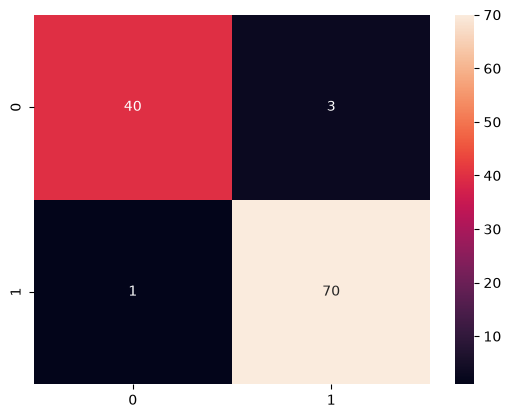

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

pred = rf_model.predict(X_test)
cm = confusion_matrix(y_test, pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.show()